# Consumo de carnes no Brasil (1990–2026): o que explica e o que prevê o consumo de carne suína?

**Pós-Graduação em Ciência de Dados e Inteligência Artificial — UniSENAI SC**
**Unidade Curricular:** Estatística Aplicada à Análise de Dados — Avaliação 2 (Projeto Aplicado)
**Autores:** Vitor Moroni e Geovani Nepomuceno

---

## 1. Introdução e definição do problema

### 1.1 Contexto e justificativa
O consumo per capita de carnes é um indicador estratégico para o agronegócio brasileiro: orienta o planejamento de abates, estoques e logística de frigoríficos, cooperativas e integradoras, como as do polo produtor de Santa Catarina. Entre as proteínas, a carne suína é a que mais mudou de patamar no país nas últimas décadas, e entender essa trajetória ajuda a dimensionar a demanda do mercado interno.

### 1.2 Problema e objetivos
**Pergunta central:** como evoluiu o consumo de carne suína no Brasil, ele se relaciona com o consumo das outras carnes e é possível prevê-lo com um ano de antecedência?

Objetivos específicos:
1. Estruturar a série brasileira a partir de uma base mundial e tratar dados ausentes, comparando métodos de imputação.
2. Descrever o comportamento de cada tipo de carne (posição, dispersão, forma e evolução).
3. Situar o Brasil no contexto mundial por meio de amostragem estratificada.
4. Quantificar cenários com modelos de probabilidade (Normal e Binomial).
5. Testar hipóteses sobre a mudança de patamar do consumo e sobre a relação entre as carnes.
6. Comparar modelos de previsão e escolher o melhor com critérios objetivos.

### 1.3 Base de dados e dicionário de variáveis
A base é a *Worldwide Meat Consumption* (Kaggle), derivada do relatório **OECD-FAO Agricultural Outlook**. O arquivo `meat_consumption_worldwide.csv` acompanha este notebook e tem 13.760 linhas em formato longo:

| Coluna original | Descrição |
|---|---|
| `LOCATION` | Código do país ou bloco (48 no total; `BRA` = Brasil) |
| `SUBJECT` | Tipo de carne: `BEEF` (bovina), `PIG` (suína), `POULTRY` (aves), `SHEEP` (ovina) |
| `MEASURE` | Unidade: `KG_CAP` (kg por habitante/ano) ou `THND_TONNE` (mil toneladas) |
| `TIME` | Ano, de 1990 a 2026 |
| `Value` | Valor do consumo na unidade indicada |

Depois da preparação, a tabela de trabalho do Brasil tem uma linha por ano:

| Variável | Descrição | Papel na análise |
|---|---|---|
| `Ano` | Ano de referência (1990–2026) | Índice temporal |
| `Carne_Suina` | Consumo de carne suína (kg/hab/ano) | **Variável de interesse (alvo)** |
| `Carne_Bovina` | Consumo de carne bovina (kg/hab/ano) | Explicativa |
| `Aves` | Consumo de carne de aves (kg/hab/ano) | Explicativa |
| `Ovinos` | Consumo de carne ovina (kg/hab/ano) | Apenas descritiva (ver Seção 4) |
| `Tipo` | `Observado` (1990–2016) ou `Projeção OCDE-FAO` (2017–2026) | Separa histórico de projeção |

> **Atenção aos anos finais.** A descrição da base informa que ela inclui projeções até 2026. Adotamos 2016 como último ano observado, pois o horizonte até 2026 corresponde à edição 2017–2026 do relatório. Por isso, **todas as estatísticas, testes e modelos usam apenas 1990–2016**; as projeções servem só como referência de comparação.

### 1.4 Etapas da análise
| Seção | Etapa | O que é feito |
|---|---|---|
| 2 | Carregamento e preparação | Leitura, diagnóstico de qualidade, filtro do Brasil e reorganização da tabela |
| 3 | Dados ausentes | Simulação de falhas de coleta e comparação de 6 métodos de imputação |
| 4 | Análise descritiva | Medidas-resumo, evolução temporal, distribuições e correlações |
| 5 | Amostragem | Amostragem aleatória simples x estratificada por país na base mundial |
| 6 | Probabilidade | Distribuições Normal e Binomial aplicadas ao consumo de carne suína |
| 7 | Inferência | Teste t de Welch, teste de correlação e intervalo de confiança |
| 8 | Modelagem | Comparação de 5 modelos de previsão e escolha do melhor |
| 9 | Conclusões | Respostas às perguntas do projeto, limitações e recomendações |

### 1.5 Diferencial do projeto
Os trabalhos públicos com esta base costumam comparar países ou rankings mundiais. Aqui o recorte é o **mercado brasileiro de carne suína**, com três elementos próprios: (i) um experimento controlado de imputação, em que os valores apagados são conhecidos e o erro de cada método pode ser medido; (ii) a separação entre dados observados e projeções da OCDE-FAO, usadas como referência externa; e (iii) a comparação dos modelos contra uma previsão ingênua, para verificar se eles de fato agregam informação.

## 2. Carregamento e preparação dos dados

Carregamos as bibliotecas, definimos a identidade visual dos gráficos (uma cor fixa para cada tipo de carne em todo o relatório) e lemos o arquivo. Em seguida verificamos tipos, valores ausentes e duplicidades.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (habilita o IterativeImputer)
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

# Identidade visual única para todo o relatório
CORES = {'Carne_Bovina': '#A93226', 'Carne_Suina': '#2E86C1', 'Aves': '#E59E0B', 'Ovinos': '#6C7A89'}
ROTULOS = {'Carne_Bovina': 'Carne bovina', 'Carne_Suina': 'Carne suína', 'Aves': 'Aves', 'Ovinos': 'Ovinos'}
CINZA = '#7F8C8D'
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
                     'axes.spines.top': False, 'axes.spines.right': False})

ARQUIVO = 'meat_consumption_worldwide.csv'
if not os.path.exists(ARQUIVO):
    # No Colab: abre o seletor para enviar o CSV entregue junto com este notebook
    from google.colab import files
    print(f'Envie o arquivo {ARQUIVO}:')
    files.upload()

df_bruto = pd.read_csv(ARQUIVO)
print(f'Dimensão da base bruta: {df_bruto.shape[0]:,} linhas x {df_bruto.shape[1]} colunas')
df_bruto.head()

Dimensão da base bruta: 13,760 linhas x 5 colunas


,LOCATION,SUBJECT,MEASURE,TIME,Value
0,AUS,BEEF,KG_CAP,1991,27.722
1,AUS,BEEF,KG_CAP,1992,26.200
2,AUS,BEEF,KG_CAP,1993,26.169
3,AUS,BEEF,KG_CAP,1994,25.456
4,AUS,BEEF,KG_CAP,1995,25.340


In [2]:
# Diagnóstico de qualidade da base bruta
print('Tipos de dados:');  print(df_bruto.dtypes.to_string())
print('\nValores ausentes por coluna:'); print(df_bruto.isnull().sum().to_string())
print(f"\nLinhas duplicadas (país + carne + medida + ano): {df_bruto.duplicated(['LOCATION', 'SUBJECT', 'MEASURE', 'TIME']).sum()}")
print(f"Países/blocos: {df_bruto['LOCATION'].nunique()} | Período: {df_bruto['TIME'].min()} a {df_bruto['TIME'].max()}")
print(f"Tipos de carne: {df_bruto['SUBJECT'].unique().tolist()}")
print(f"Unidades de medida: {df_bruto['MEASURE'].unique().tolist()}")

Tipos de dados:
LOCATION        str
SUBJECT         str
MEASURE         str
TIME          int64
Value       float64

Valores ausentes por coluna:
LOCATION    0
SUBJECT     0
MEASURE     0
TIME        0
Value       0

Linhas duplicadas (país + carne + medida + ano): 0
Países/blocos: 48 | Período: 1990 a 2026
Tipos de carne: ['BEEF', 'PIG', 'POULTRY', 'SHEEP']
Unidades de medida: ['KG_CAP', 'THND_TONNE']


### 2.1 Filtro do Brasil e reorganização da tabela

A base bruta **não tem valores ausentes nem duplicidades**. Cada combinação país–carne–ano aparece duas vezes, uma para cada unidade de medida. Tomamos três decisões de preparação:

* **Unidade:** mantemos apenas `KG_CAP`. O volume total em mil toneladas (`THND_TONNE`) cresce junto com a população e não permite comparar hábitos de consumo entre épocas ou países.
* **Recorte geográfico:** filtramos `BRA`; os demais países voltam a ser usados na etapa de amostragem (Seção 5).
* **Formato:** passamos do formato longo para o largo (uma linha por ano, uma coluna por carne), que é o formato exigido pelas análises seguintes.

In [3]:
RENOMEAR = {'TIME': 'Ano', 'BEEF': 'Carne_Bovina', 'PIG': 'Carne_Suina', 'POULTRY': 'Aves', 'SHEEP': 'Ovinos'}
colunas_num = ['Carne_Bovina', 'Carne_Suina', 'Aves', 'Ovinos']
ULTIMO_ANO_OBSERVADO = 2016   # de 2017 em diante a base traz projeções da OCDE-FAO

# Mantemos apenas o consumo per capita (KG_CAP); o volume total (THND_TONNE) depende do tamanho da população
df_kg = df_bruto[df_bruto['MEASURE'] == 'KG_CAP']

# Formato longo -> formato largo: uma linha por ano, uma coluna por tipo de carne
df_brasil = (df_kg[df_kg['LOCATION'] == 'BRA']
             .pivot(index='TIME', columns='SUBJECT', values='Value')
             .reset_index().rename(columns=RENOMEAR))
df_brasil.columns.name = None
df_brasil = df_brasil[['Ano'] + colunas_num]

print(f'Brasil: {len(df_brasil)} anos ({df_brasil.Ano.min()}-{df_brasil.Ano.max()}), '
      f'sendo {(df_brasil.Ano <= ULTIMO_ANO_OBSERVADO).sum()} observados e {(df_brasil.Ano > ULTIMO_ANO_OBSERVADO).sum()} projetados.')
print(f'Valores ausentes na série brasileira original: {int(df_brasil[colunas_num].isnull().sum().sum())}')
df_brasil.head()

Brasil: 37 anos (1990-2026), sendo 27 observados e 10 projetados.
Valores ausentes na série brasileira original: 0


,Ano,Carne_Bovina,Carne_Suina,Aves,Ovinos
0,1990,19.276,5.394,12.036,0.669
1,1991,19.361,5.580,13.271,0.667
2,1992,18.834,5.733,14.166,0.662
3,1993,18.971,5.857,15.203,0.676
4,1994,21.128,6.274,16.171,0.649


## 3. Tratamento de dados ausentes (imputação)

A série brasileira original está completa. Para exercitar e **avaliar** técnicas de imputação, simulamos um problema comum em séries de mercado: falhas de coleta. Apagamos ao acaso cerca de 10% dos valores de carne suína e bovina (mecanismo MCAR, *missing completely at random*).

A vantagem de simular é que conhecemos o valor verdadeiro de cada lacuna, o que permite medir o erro de cada método em vez de escolher um por preferência. Comparamos seis alternativas, da mais simples à mais avançada:

| Método | Como preenche a lacuna |
|---|---|
| Média | Média da coluna (referência mínima) |
| Interpolação linear | Reta entre o ano anterior e o ano seguinte |
| KNN simples (k=2) | Média dos 2 anos mais parecidos no consumo das outras carnes |
| KNN temporal (k=3 e k=5) | KNN com o `Ano` como variável, dados padronizados e peso pela distância |
| MICE (`IterativeImputer`) | Regressões encadeadas: cada variável é prevista pelas demais |

Medimos o erro de duas formas: no cenário simulado (semente 42) e, como ele tem apenas 10 lacunas, em uma **validação Monte Carlo com 200 padrões diferentes de falhas**, que dá um resultado menos dependente da sorte.

In [4]:
# 3.1 Simulação de falhas de coleta: ~10% dos valores de carne suína e bovina são apagados ao acaso (MCAR)
df_real = df_brasil.copy()                      # gabarito: valores verdadeiros
np.random.seed(42)
mascara = np.random.rand(len(df_brasil), 2) < 0.10
df_falhas = df_brasil.copy()
df_falhas[['Carne_Suina', 'Carne_Bovina']] = df_falhas[['Carne_Suina', 'Carne_Bovina']].mask(mascara)

print('Valores ausentes após a simulação:')
print(df_falhas[colunas_num].isnull().sum().to_string())
print(f"\nAnos afetados: {df_falhas.loc[df_falhas[colunas_num].isnull().any(axis=1), 'Ano'].tolist()}")

Valores ausentes após a simulação:
Carne_Bovina    2
Carne_Suina     8
Aves            0
Ovinos          0

Anos afetados: [1993, 1995, 2004, 2006, 2008, 2011, 2018, 2019, 2024, 2026]


In [5]:
# 3.2 Métodos de imputação candidatos
COLS_T = ['Ano'] + colunas_num

def imp_media(df):
    out = df.copy(); out[colunas_num] = SimpleImputer(strategy='mean').fit_transform(df[colunas_num]); return out

def imp_interpolacao(df):
    out = df.copy(); out[colunas_num] = df[colunas_num].interpolate(method='linear', limit_direction='both'); return out

def imp_knn_simples(df, k=2):
    # Versão inicial do projeto: vizinhos definidos só pelo consumo das outras carnes, sem padronizar
    out = df.copy(); out[colunas_num] = KNNImputer(n_neighbors=k).fit_transform(df[colunas_num]); return out

def imp_knn_temporal(df, k=5):
    # KNN com o Ano como variável, dados padronizados e vizinhos ponderados pela distância
    sc = StandardScaler(); z = sc.fit_transform(df[COLS_T])
    z = KNNImputer(n_neighbors=k, weights='distance').fit_transform(z)
    out = df.copy(); out[COLS_T] = sc.inverse_transform(z); out['Ano'] = df['Ano'].values; return out

def imp_mice(df):
    # MICE: cada variável com falhas é prevista por regressão a partir das demais, de forma iterativa
    out = df.copy(); out[COLS_T] = IterativeImputer(random_state=42, max_iter=50).fit_transform(df[COLS_T])
    out['Ano'] = df['Ano'].values; return out

METODOS = {
    'Média': imp_media,
    'Interpolação linear': imp_interpolacao,
    'KNN simples (k=2)': imp_knn_simples,
    'KNN temporal (k=3)': lambda d: imp_knn_temporal(d, 3),
    'KNN temporal (k=5)': lambda d: imp_knn_temporal(d, 5),
    'MICE (IterativeImputer)': imp_mice,
}

def erro_imputacao(df_com_falhas, df_imputado):
    falhas = df_com_falhas[colunas_num].isnull().values
    erro = (df_imputado[colunas_num].values - df_real[colunas_num].values)[falhas]
    return np.abs(erro).mean(), np.sqrt((erro ** 2).mean())

# (a) Erro no cenário simulado acima (semente 42)
linhas = []
for nome, f in METODOS.items():
    mae, rmse = erro_imputacao(df_falhas, f(df_falhas))
    linhas.append({'Método': nome, 'MAE (semente 42)': mae, 'RMSE (semente 42)': rmse})
tab_imp = pd.DataFrame(linhas).set_index('Método')

# (b) Validação Monte Carlo: repete a simulação com 200 padrões diferentes de falhas
rng = np.random.default_rng(2026)
acum = {nome: [] for nome in METODOS}
for _ in range(200):
    m = rng.random((len(df_real), 2)) < 0.10
    if m.sum() == 0:
        continue
    d = df_real.copy()
    d[['Carne_Suina', 'Carne_Bovina']] = d[['Carne_Suina', 'Carne_Bovina']].mask(m)
    for nome, f in METODOS.items():
        acum[nome].append(erro_imputacao(d, f(d))[1])
tab_imp['RMSE médio (200 simulações)'] = pd.Series({k: np.mean(v) for k, v in acum.items()})
tab_imp['Desvio do RMSE'] = pd.Series({k: np.std(v) for k, v in acum.items()})
tab_imp = tab_imp.sort_values('RMSE médio (200 simulações)')
METODO_ESCOLHIDO = tab_imp.index[0]
print('Erro de imputação em kg/hab (quanto menor, melhor):')
display(tab_imp)
print(f'Método com menor RMSE médio: {METODO_ESCOLHIDO}')

Erro de imputação em kg/hab (quanto menor, melhor):


,MAE (semente 42),RMSE (semente 42),RMSE médio (200 simulações),Desvio do RMSE
Método,,,,
Interpolação linear,0.244,0.341,0.502,0.232
KNN simples (k=2),0.361,0.395,0.747,0.306
KNN temporal (k=3),0.297,0.411,0.774,0.410
KNN temporal (k=5),0.249,0.305,0.792,0.388
MICE (IterativeImputer),0.283,0.345,0.892,0.397
Média,2.190,2.593,2.290,0.668


Método com menor RMSE médio: Interpolação linear


Valores ausentes após a imputação (Interpolação linear): 0


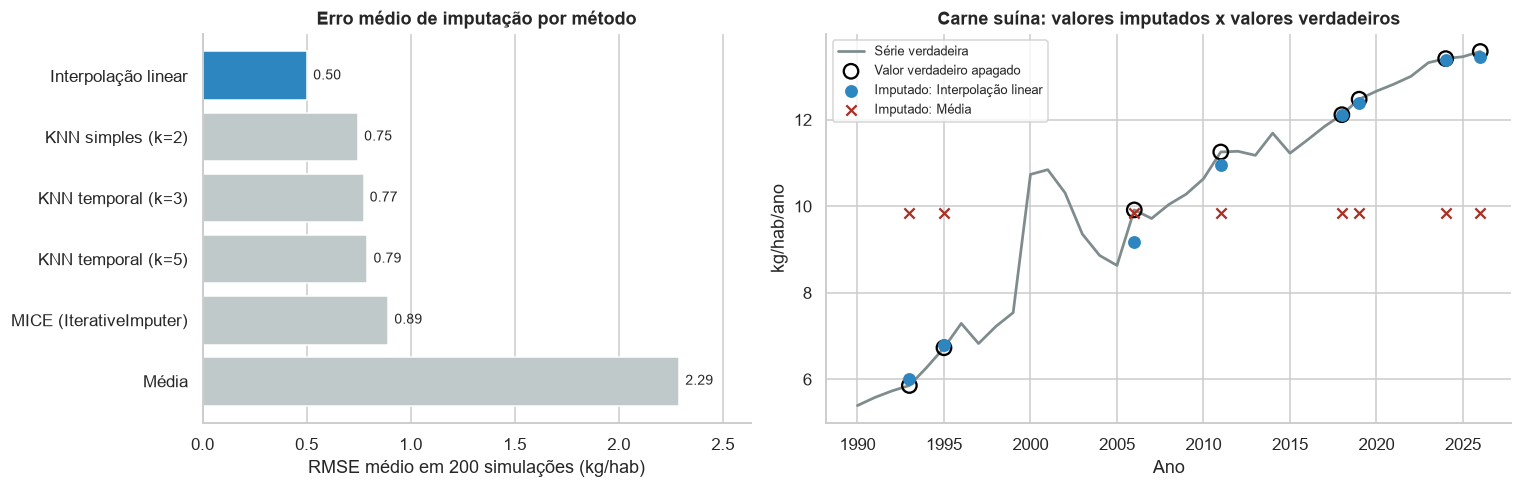

In [6]:
# 3.3 Aplicação do método escolhido e conferência visual
df_projeto = METODOS[METODO_ESCOLHIDO](df_falhas)
df_projeto['Tipo'] = np.where(df_projeto['Ano'] <= ULTIMO_ANO_OBSERVADO, 'Observado', 'Projeção OCDE-FAO')
print(f'Valores ausentes após a imputação ({METODO_ESCOLHIDO}): {int(df_projeto[colunas_num].isnull().sum().sum())}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1, 1.25]})
ordem = tab_imp['RMSE médio (200 simulações)']
cores_barras = ['#2E86C1' if i == METODO_ESCOLHIDO else '#BFC9CA' for i in ordem.index]
axes[0].barh(ordem.index[::-1], ordem.values[::-1], color=cores_barras[::-1])
for y, v in enumerate(ordem.values[::-1]):
    axes[0].text(v + 0.03, y, f'{v:.2f}', va='center', fontsize=9)
axes[0].set_title('Erro médio de imputação por método'); axes[0].set_xlabel('RMSE médio em 200 simulações (kg/hab)')
axes[0].set_xlim(0, ordem.max() * 1.15); axes[0].grid(axis='y', visible=False)

falhou = df_falhas['Carne_Suina'].isnull()
axes[1].plot(df_real['Ano'], df_real['Carne_Suina'], color=CINZA, lw=1.8, label='Série verdadeira')
axes[1].scatter(df_real.loc[falhou, 'Ano'], df_real.loc[falhou, 'Carne_Suina'], s=90, facecolors='none',
                edgecolors='black', lw=1.5, label='Valor verdadeiro apagado', zorder=3)
axes[1].scatter(df_projeto.loc[falhou, 'Ano'], df_projeto.loc[falhou, 'Carne_Suina'], s=55, color=CORES['Carne_Suina'],
                label=f'Imputado: {METODO_ESCOLHIDO}', zorder=4)
media_imp = imp_media(df_falhas)
axes[1].scatter(media_imp.loc[falhou, 'Ano'], media_imp.loc[falhou, 'Carne_Suina'], s=45, marker='x', color='#A93226',
                label='Imputado: Média', zorder=4)
axes[1].set_title('Carne suína: valores imputados x valores verdadeiros')
axes[1].set_xlabel('Ano'); axes[1].set_ylabel('kg/hab/ano'); axes[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

### 3.4 Método escolhido e justificativa

**Escolhemos a interpolação linear**, pelo critério de menor erro médio na validação Monte Carlo:

* Nas 200 simulações, a interpolação teve RMSE médio de **0,50 kg/hab**, contra 0,75 a 0,79 do KNN e 0,89 do MICE. A média simples erra 2,29 kg/hab, mais de quatro vezes o erro da interpolação.
* No cenário único da semente 42, o KNN temporal (k=5) chegou a ter erro um pouco menor (0,31 contra 0,34), mas essa vantagem não se repete quando o padrão de falhas muda. Por isso a decisão se apoia nas 200 repetições, não em um único sorteio.
* **Por que o método mais simples venceu:** o consumo anual muda de forma gradual, então os melhores "vizinhos" de um ano são o ano anterior e o seguinte, exatamente o que a interpolação usa. KNN e MICE buscam semelhança no consumo das outras carnes, que, como a Seção 4 mostra, tem pouca relação de curto prazo com a carne suína.
* **Por que a média é inadequada:** em uma série com tendência, ela coloca o mesmo valor (perto de 9,8 kg) em 1993 e em 2026, como mostram os "x" vermelhos do gráfico.

A partir daqui trabalhamos com a base imputada (`df_projeto`): 10 dos 148 valores foram preenchidos por interpolação. A limitação conhecida do método é a lacuna na ponta da série (2026), que repete o último valor disponível.

## 4. Análise descritiva

Descrevemos as quatro variáveis no **período observado (1990–2016)**. A tabela reúne medidas de posição (média, mediana, quartis), dispersão (desvio padrão e coeficiente de variação, CV) e forma (assimetria e curtose).

In [7]:
df_obs = df_projeto[df_projeto['Tipo'] == 'Observado'].reset_index(drop=True)
df_proj = df_projeto[df_projeto['Tipo'] != 'Observado'].reset_index(drop=True)

# 4.1 Medidas de posição, dispersão e forma (período observado, 1990-2016)
desc = df_obs[colunas_num].describe().T
desc['mediana'] = df_obs[colunas_num].median()
desc['CV (%)'] = desc['std'] / desc['mean'] * 100
desc['assimetria'] = df_obs[colunas_num].skew()
desc['curtose'] = df_obs[colunas_num].kurt()
desc['variação 1990-2016 (%)'] = (df_obs[colunas_num].iloc[-1] / df_obs[colunas_num].iloc[0] - 1) * 100
desc = desc.rename(index=ROTULOS, columns={'count': 'n', 'mean': 'média', 'std': 'desvio padrão', 'min': 'mínimo', 'max': 'máximo'})
desc[['n', 'média', 'mediana', 'desvio padrão', 'CV (%)', 'mínimo', '25%', '75%', 'máximo', 'assimetria', 'curtose', 'variação 1990-2016 (%)']].round(2)

,n,média,mediana,desvio padrão,CV (%),mínimo,25%,75%,máximo,assimetria,curtose,variação 1990-2016 (%)
Carne bovina,27.000,23.760,24.500,2.290,9.640,18.830,23.380,25.260,26.500,-1.160,0.410,33.120
Carne suína,27.000,8.930,9.360,2.110,23.670,5.390,7.020,10.790,11.690,-0.360,-1.400,113.730
Aves,27.000,28.110,28.920,9.370,33.350,12.040,20.410,36.750,40.720,-0.260,-1.260,229.010
Ovinos,27.000,0.460,0.400,0.120,26.180,0.340,0.390,0.550,0.690,1.050,-0.690,-41.810


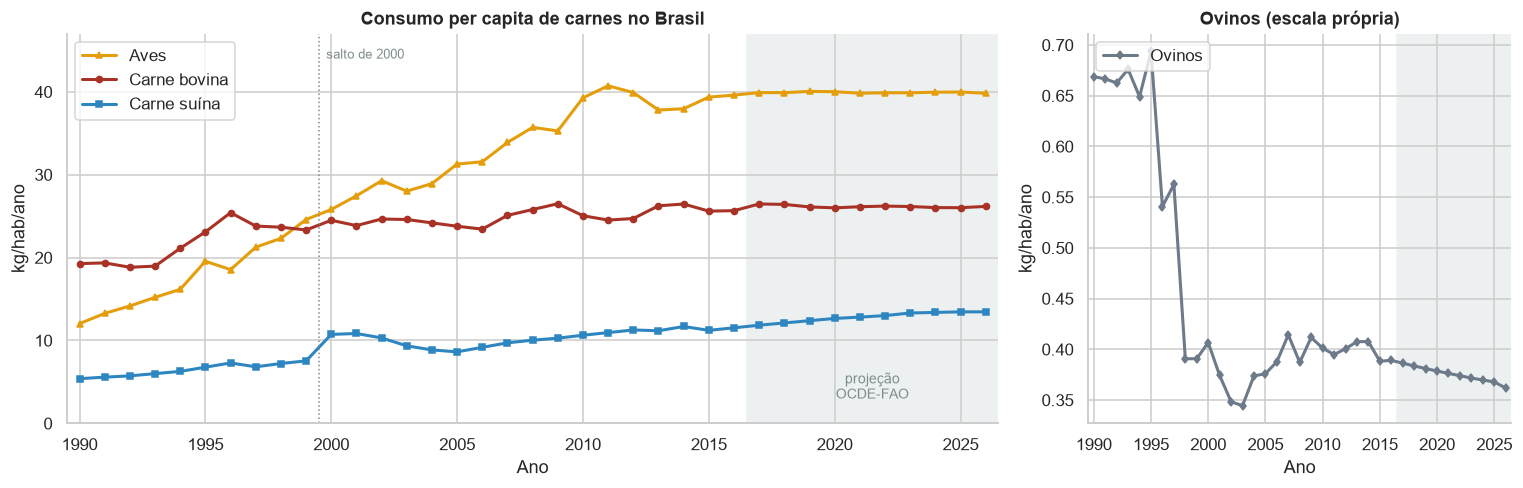

In [8]:
# 4.2 Evolução temporal
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [2.2, 1]})
for c, m in zip(['Aves', 'Carne_Bovina', 'Carne_Suina'], ['^', 'o', 's']):
    axes[0].plot(df_projeto['Ano'], df_projeto[c], color=CORES[c], marker=m, ms=4, lw=2, label=ROTULOS[c])
axes[1].plot(df_projeto['Ano'], df_projeto['Ovinos'], color=CORES['Ovinos'], marker='d', ms=4, lw=2, label=ROTULOS['Ovinos'])
for ax in axes:
    ax.axvspan(ULTIMO_ANO_OBSERVADO + 0.5, df_projeto['Ano'].max() + 0.5, color='#ECF0F1', zorder=0)
    ax.set_xlabel('Ano'); ax.set_ylabel('kg/hab/ano'); ax.set_xlim(1989.5, 2026.5); ax.legend(loc='upper left')
axes[0].text(2021.5, 3, 'projeção\nOCDE-FAO', ha='center', color=CINZA, fontsize=9)
axes[0].axvline(1999.5, color=CINZA, ls=':', lw=1); axes[0].text(1999.8, 44, 'salto de 2000', color=CINZA, fontsize=8.5)
axes[0].set_ylim(0, 47)
axes[0].set_title('Consumo per capita de carnes no Brasil'); axes[1].set_title('Ovinos (escala própria)')
plt.tight_layout(); plt.show()

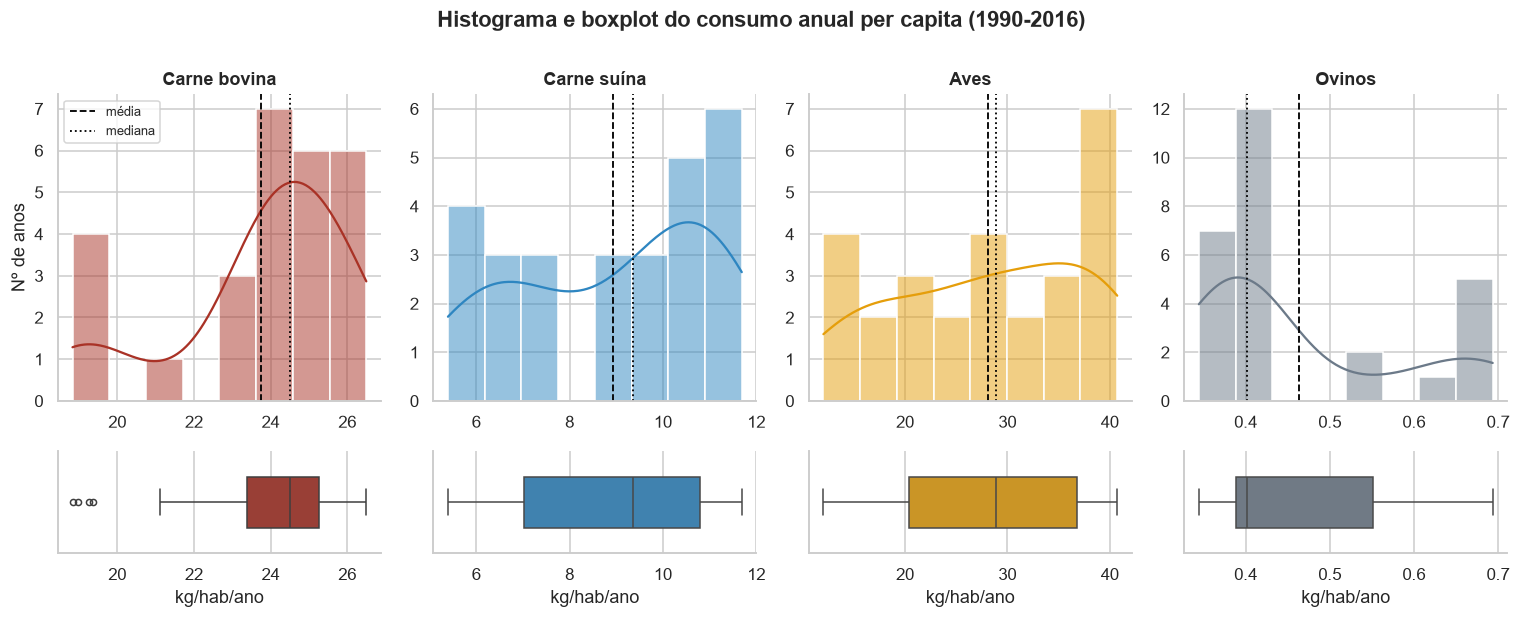

In [9]:
# 4.3 Distribuição de cada variável (período observado)
fig, axes = plt.subplots(2, 4, figsize=(14, 5.6), gridspec_kw={'height_ratios': [3, 1]})
for j, c in enumerate(colunas_num):
    sns.histplot(df_obs[c], bins=8, kde=True, color=CORES[c], ax=axes[0, j], edgecolor='white')
    axes[0, j].axvline(df_obs[c].mean(), color='black', ls='--', lw=1.2, label='média')
    axes[0, j].axvline(df_obs[c].median(), color='black', ls=':', lw=1.2, label='mediana')
    axes[0, j].set_title(ROTULOS[c]); axes[0, j].set_xlabel(''); axes[0, j].set_ylabel('Nº de anos' if j == 0 else '')
    sns.boxplot(x=df_obs[c], color=CORES[c], ax=axes[1, j], width=0.5, fliersize=4)
    axes[1, j].set_xlabel('kg/hab/ano'); axes[1, j].set_xlim(axes[0, j].get_xlim())
axes[0, 0].legend(fontsize=8.5)
fig.suptitle('Histograma e boxplot do consumo anual per capita (1990-2016)', fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()

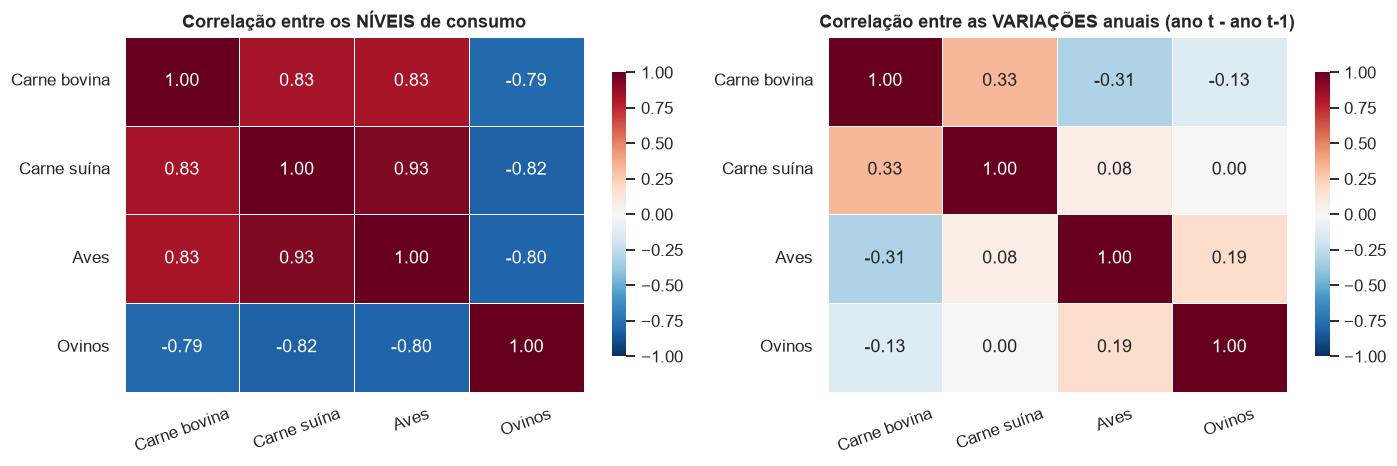

In [10]:
# 4.4 Correlação: níveis x variações anuais
corr_nivel = df_obs[colunas_num].corr().rename(index=ROTULOS, columns=ROTULOS)
corr_var = df_obs[colunas_num].diff().dropna().corr().rename(index=ROTULOS, columns=ROTULOS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, m, t in zip(axes, [corr_nivel, corr_var],
                    ['Correlação entre os NÍVEIS de consumo', 'Correlação entre as VARIAÇÕES anuais (ano t - ano t-1)']):
    sns.heatmap(m, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, linewidths=.6, ax=ax, cbar_kws={'shrink': .8})
    ax.set_title(t); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

### 4.5 Leitura dos resultados

**Evolução.** O frango foi a proteína que mais cresceu: de 12,0 para 39,6 kg/hab entre 1990 e 2016 (+229%), ultrapassando a carne bovina no fim dos anos 1990. A carne suína mais que dobrou (+114%, de 5,4 para 11,5 kg/hab). A bovina cresceu 33% e está praticamente estável desde meados dos anos 1990, entre 23 e 26,5 kg/hab. O consumo de ovinos caiu 42% e é residual.

**Salto de 2000.** O consumo de carne suína passa de 7,5 kg/hab em 1999 para 10,7 em 2000, uma variação de mais de 3 kg em um único ano, sem paralelo no restante da série. Um salto desse tamanho pode refletir uma revisão metodológica da fonte além de uma mudança real de consumo, e isso é considerado na leitura dos testes e modelos.

**Dispersão e forma.** Aves (CV de 33%) e carne suína (24%) são as séries mais dispersas, justamente por terem tendência forte; a bovina é a mais estável (CV de 9,6%). Os histogramas não têm formato de sino: os da carne suína e das aves são achatados e com dois agrupamentos (curtose negativa), reflexo da mudança de patamar ao longo do tempo. A carne bovina tem assimetria negativa (−1,16) e valores atípicos baixos no boxplot, que são os quatro anos de 1990 a 1993, anteriores à alta de meados da década.

**Correlação.** Nos níveis, as correlações são altas e positivas (0,93 entre suína e aves). Isso **não indica substituição entre carnes**; indica que todas cresceram no mesmo período, o que é uma correlação inflada pela tendência comum. Quando olhamos as **variações anuais**, a correlação entre suína e aves cai para 0,08. A significância dessas correlações é testada na Seção 7.

### 4.6 Variáveis excluídas e motivos

| Variável ou recorte | Decisão | Motivo |
|---|---|---|
| `MEASURE = THND_TONNE` | Excluída | Volume total depende do tamanho da população; o objetivo é analisar o consumo por habitante |
| `Ovinos` | Mantida só na descritiva | Consumo médio de 0,46 kg/hab/ano, menos de 1% do total de carnes; não é uma alternativa relevante à carne suína |
| Anos 2017–2026 | Excluídos de estatísticas, testes e modelos | São projeções, não observações; ficam como referência de comparação |
| Agregados `WLD`, `OECD`, `BRICS`, `SSA` | Excluídos da amostragem | Somam países já presentes na base e gerariam dupla contagem |

## 5. Amostragem

**Por que amostrar neste projeto.** Para saber se o consumo brasileiro de carne suína é alto ou baixo, precisamos de uma referência mundial. Tratamos os registros país–ano da base como a população e estimamos a média mundial a partir de uma amostra, como se faria em uma pesquisa em que não é viável levantar todos os dados.

**Técnica escolhida: amostragem estratificada proporcional, com o país como estrato.** A escolha se justifica pela estrutura dos dados: o consumo de carne suína varia muito *entre* países (por renda, cultura e religião) e pouco *dentro* de cada país ao longo dos anos. Essa é a situação em que a estratificação mais ganha em precisão. Sorteamos 30% dos anos de cada país e comparamos com uma **amostragem aleatória simples (AAS)** de mesmo tamanho.

In [11]:
# 5.1 População de referência: registros país-ano de consumo de carne suína (1990-2016)
AGREGADOS = ['WLD', 'OECD', 'BRICS', 'SSA']   # agregados regionais: somam países já listados
df_mundo = (df_kg[(df_kg['SUBJECT'] == 'PIG') & (df_kg['TIME'] <= ULTIMO_ANO_OBSERVADO) & (~df_kg['LOCATION'].isin(AGREGADOS))]
            .rename(columns={'LOCATION': 'Pais', 'TIME': 'Ano', 'Value': 'Carne_Suina'})[['Pais', 'Ano', 'Carne_Suina']]
            .dropna().reset_index(drop=True))
N = len(df_mundo); mu = df_mundo['Carne_Suina'].mean()
print(f'População: {N} registros país-ano | {df_mundo.Pais.nunique()} países/blocos (estratos)')
print(f'Parâmetro populacional (média do consumo de carne suína): {mu:.3f} kg/hab/ano')
print(f"Desvio padrão total: {df_mundo.Carne_Suina.std():.2f} | desvio padrão médio DENTRO dos países: {df_mundo.groupby('Pais').Carne_Suina.std().mean():.2f}")

População: 1122 registros país-ano | 42 países/blocos (estratos)
Parâmetro populacional (média do consumo de carne suína): 7.967 kg/hab/ano
Desvio padrão total: 8.73 | desvio padrão médio DENTRO dos países: 1.49


Tamanho das amostras: n = 334 (30% da população)
Média populacional ........: 7.967
Estimativa AAS ............: 7.612  (erro -0.356)
Estimativa estratificada ..: 7.940  (erro -0.027)
Países presentes -> AAS: 42 | Estratificada: 42 de 42



Erro padrão empírico (1.000 sorteios) -> AAS: 0.400 | Estratificada: 0.105 (redução de 74%)


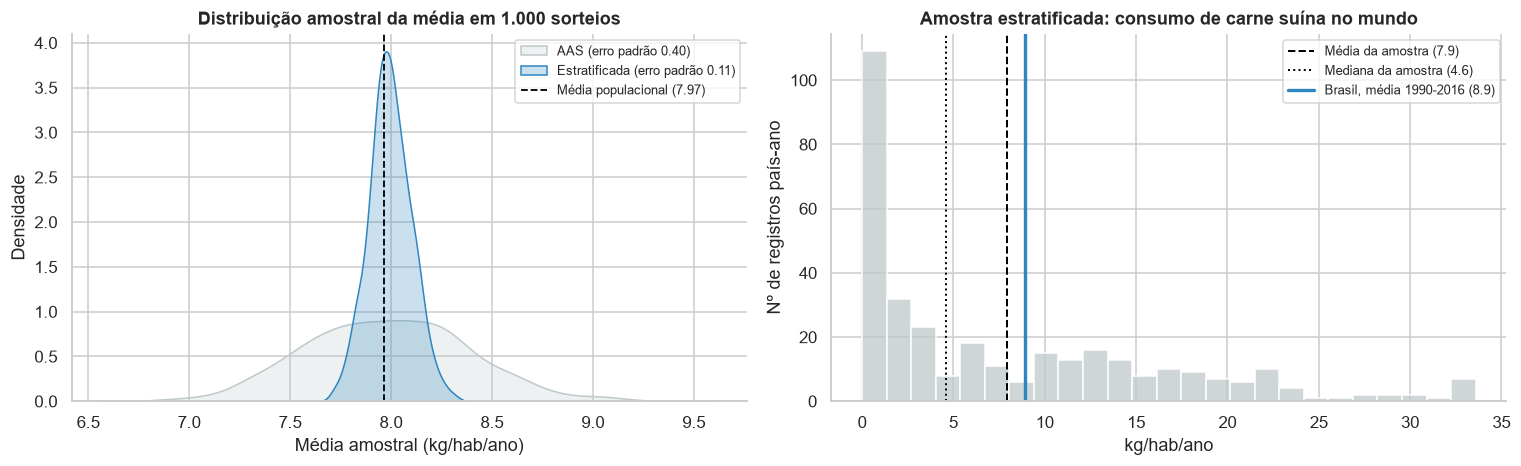

In [12]:
# 5.2 Amostragem aleatória simples (AAS) x amostragem estratificada proporcional por país (fração de 30%)
FRACAO = 0.30
amostra_estrat = df_mundo.groupby('Pais', group_keys=False).sample(frac=FRACAO, random_state=42)
n = len(amostra_estrat)
amostra_aas = df_mundo.sample(n=n, random_state=42)
print(f'Tamanho das amostras: n = {n} ({n / N:.0%} da população)')
print(f'Média populacional ........: {mu:.3f}')
print(f'Estimativa AAS ............: {amostra_aas.Carne_Suina.mean():.3f}  (erro {amostra_aas.Carne_Suina.mean() - mu:+.3f})')
print(f'Estimativa estratificada ..: {amostra_estrat.Carne_Suina.mean():.3f}  (erro {amostra_estrat.Carne_Suina.mean() - mu:+.3f})')
print(f'Países presentes -> AAS: {amostra_aas.Pais.nunique()} | Estratificada: {amostra_estrat.Pais.nunique()} de {df_mundo.Pais.nunique()}')

# Repetimos o sorteio 1.000 vezes para comparar a precisão dos dois planos amostrais
est_aas, est_est = [], []
for s in range(1000):
    est_aas.append(df_mundo.sample(n=n, random_state=s).Carne_Suina.mean())
    est_est.append(df_mundo.groupby('Pais', group_keys=False).sample(frac=FRACAO, random_state=s).Carne_Suina.mean())
ep_aas, ep_est = np.std(est_aas), np.std(est_est)
print(f'\nErro padrão empírico (1.000 sorteios) -> AAS: {ep_aas:.3f} | Estratificada: {ep_est:.3f} '
      f'(redução de {(1 - ep_est / ep_aas):.0%})')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.kdeplot(est_aas, fill=True, color='#BFC9CA', label=f'AAS (erro padrão {ep_aas:.2f})', ax=axes[0])
sns.kdeplot(est_est, fill=True, color=CORES['Carne_Suina'], label=f'Estratificada (erro padrão {ep_est:.2f})', ax=axes[0])
axes[0].axvline(mu, color='black', ls='--', lw=1.2, label=f'Média populacional ({mu:.2f})')
axes[0].set_title('Distribuição amostral da média em 1.000 sorteios'); axes[0].set_xlabel('Média amostral (kg/hab/ano)')
axes[0].set_ylabel('Densidade'); axes[0].legend(fontsize=8.5)

bra_media = df_obs['Carne_Suina'].mean()
sns.histplot(amostra_estrat['Carne_Suina'], bins=25, color='#BFC9CA', edgecolor='white', ax=axes[1])
axes[1].axvline(amostra_estrat.Carne_Suina.mean(), color='black', ls='--', lw=1.3, label=f'Média da amostra ({amostra_estrat.Carne_Suina.mean():.1f})')
axes[1].axvline(amostra_estrat.Carne_Suina.median(), color='black', ls=':', lw=1.3, label=f'Mediana da amostra ({amostra_estrat.Carne_Suina.median():.1f})')
axes[1].axvline(bra_media, color=CORES['Carne_Suina'], lw=2.2, label=f'Brasil, média 1990-2016 ({bra_media:.1f})')
axes[1].set_title('Amostra estratificada: consumo de carne suína no mundo'); axes[1].set_xlabel('kg/hab/ano')
axes[1].set_ylabel('Nº de registros país-ano'); axes[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

### 5.3 Leitura dos resultados

* **A estrutura dos dados confirma a escolha:** o desvio padrão total é de 8,73 kg/hab, mas dentro de um mesmo país é, em média, de apenas 1,49.
* **A estratificação foi mais precisa.** Com as mesmas 334 observações, a amostra estratificada estimou a média em 7,94 (erro de −0,03 em relação ao valor populacional de 7,97), e a AAS, em 7,61 (erro de −0,36). Repetindo o sorteio 1.000 vezes, o erro padrão cai de 0,40 para 0,11, uma **redução de 74%**. Os dois planos são não viesados (as duas curvas estão centradas na média populacional); a diferença está na dispersão.
* **O Brasil no contexto mundial.** A distribuição mundial é muito assimétrica: a mediana é de 4,6 kg/hab e muitos países têm consumo próximo de zero. A média brasileira de 1990–2016 (8,9 kg/hab) fica acima da média e da mediana mundiais, mas longe dos grandes consumidores, que passam de 30 kg/hab.

Essa amostra estratificada é reutilizada na Seção 7 para construir um intervalo de confiança. Na modelagem (Seção 8) **não** usamos sorteio aleatório para separar treino e teste: em séries temporais isso deixaria o modelo "ver o futuro", então a separação é feita por ordem cronológica.

## 6. Aplicações em probabilidade

Usamos dois modelos para responder a perguntas de planejamento: a **distribuição Normal**, para a probabilidade de o consumo ultrapassar determinado nível, e a **distribuição Binomial**, para o número de anos de crescimento em uma década.

Antes de usar a Normal, verificamos a premissa com o teste de Shapiro-Wilk e o gráfico Q-Q. A série completa mistura dois patamares de consumo (Seção 4), então ajustamos o modelo ao patamar recente, de 2000 a 2016.

Teste de Shapiro-Wilk (H0: os dados seguem uma distribuição Normal)
  Série completa 1990-2016 : W = 0.902 | p = 0.0152 -> rejeita a normalidade
  Patamar 2000-2016        : W = 0.942 | p = 0.3406 -> não rejeita a normalidade

Modelo: X ~ Normal(média = 10.38; desvio padrão = 0.95) kg/hab/ano
  P(X > 12 kg)          = 4.33%
  P(9,5 < X < 11,5 kg)   = 70.52%   (frequência observada: 64.71%)
  Percentil 95           = 11.94 kg/hab (apenas 5% dos anos ficariam acima)


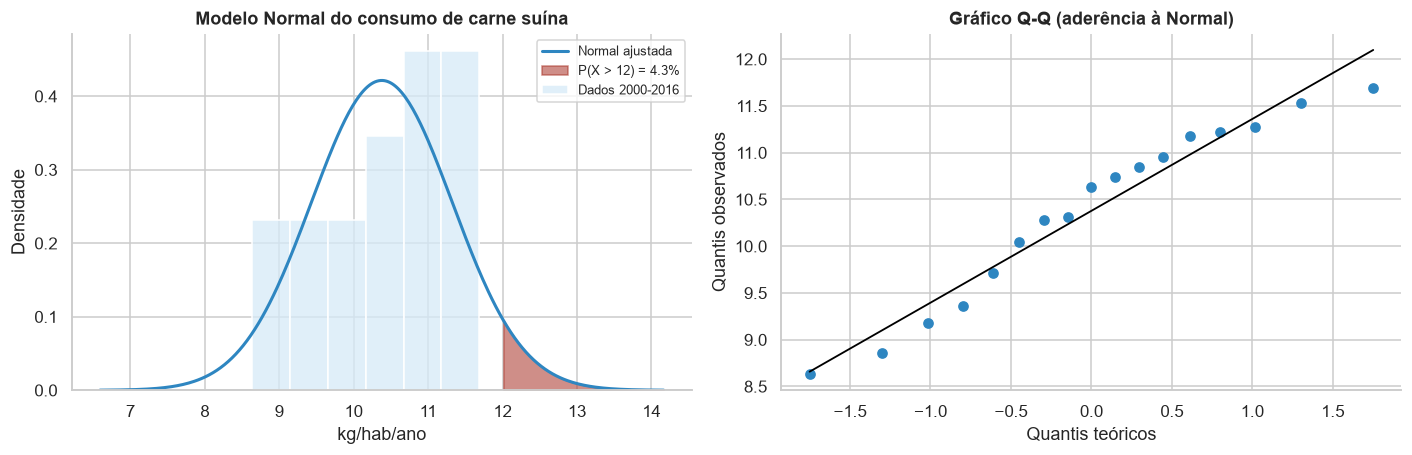

In [13]:
# 6.1 Distribuição Normal: consumo de carne suína no patamar recente (2000-2016)
suino_rec = df_obs.loc[df_obs['Ano'] >= 2000, 'Carne_Suina']
suino_tot = df_obs['Carne_Suina']
w_tot, p_tot = stats.shapiro(suino_tot); w_rec, p_rec = stats.shapiro(suino_rec)
print('Teste de Shapiro-Wilk (H0: os dados seguem uma distribuição Normal)')
print(f'  Série completa 1990-2016 : W = {w_tot:.3f} | p = {p_tot:.4f} -> {"rejeita" if p_tot < 0.05 else "não rejeita"} a normalidade')
print(f'  Patamar 2000-2016        : W = {w_rec:.3f} | p = {p_rec:.4f} -> {"rejeita" if p_rec < 0.05 else "não rejeita"} a normalidade')

mu_s, sd_s = suino_rec.mean(), suino_rec.std(ddof=1)
LIMITE = 12.0
p_acima = stats.norm.sf(LIMITE, mu_s, sd_s)
p_faixa = stats.norm.cdf(11.5, mu_s, sd_s) - stats.norm.cdf(9.5, mu_s, sd_s)
p95 = stats.norm.ppf(0.95, mu_s, sd_s)
print(f'\nModelo: X ~ Normal(média = {mu_s:.2f}; desvio padrão = {sd_s:.2f}) kg/hab/ano')
print(f'  P(X > {LIMITE:.0f} kg)          = {p_acima:.2%}')
print(f'  P(9,5 < X < 11,5 kg)   = {p_faixa:.2%}   (frequência observada: {((suino_rec > 9.5) & (suino_rec < 11.5)).mean():.2%})')
print(f'  Percentil 95           = {p95:.2f} kg/hab (apenas 5% dos anos ficariam acima)')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
x = np.linspace(mu_s - 4 * sd_s, mu_s + 4 * sd_s, 300); y = stats.norm.pdf(x, mu_s, sd_s)
sns.histplot(suino_rec, bins=6, stat='density', color='#D6EAF8', edgecolor='white', ax=axes[0], label='Dados 2000-2016')
axes[0].plot(x, y, color=CORES['Carne_Suina'], lw=2, label='Normal ajustada')
axes[0].fill_between(x, y, where=x > LIMITE, color='#A93226', alpha=.55, label=f'P(X > {LIMITE:.0f}) = {p_acima:.1%}')
axes[0].set_title('Modelo Normal do consumo de carne suína'); axes[0].set_xlabel('kg/hab/ano'); axes[0].set_ylabel('Densidade'); axes[0].legend(fontsize=8.5)
stats.probplot(suino_rec, dist='norm', plot=axes[1])
axes[1].get_lines()[0].set(color=CORES['Carne_Suina'], markersize=6); axes[1].get_lines()[1].set(color='black', lw=1.2)
axes[1].set_title('Gráfico Q-Q (aderência à Normal)'); axes[1].set_xlabel('Quantis teóricos'); axes[1].set_ylabel('Quantis observados')
plt.tight_layout(); plt.show()

Anos com crescimento entre 1991 e 2016: 19 de 26 -> p = 0.731
Modelo: Y ~ Binomial(n = 10; p = 0.731)
  Número esperado de anos de alta     = 7.3
  P(Y >= 7)  (ao menos 7 anos de alta) = 72.93%
  P(Y <= 4)  (no máximo 4 anos de alta) = 2.83%
  P(Y = 10)  (alta em todos os anos)   = 4.34%
Projeção OCDE-FAO 2017-2026: alta em 10 de 10 anos.


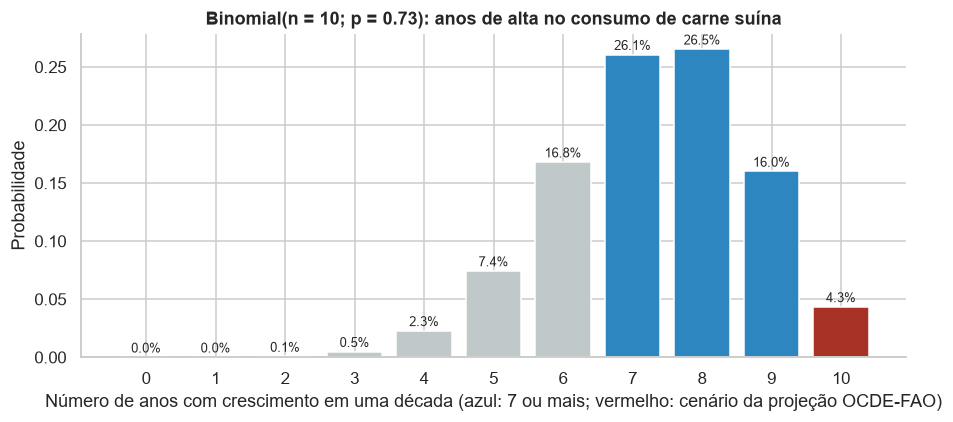

In [14]:
# 6.2 Distribuição Binomial: em quantos dos próximos 10 anos o consumo de carne suína cresce?
variacao = df_obs['Carne_Suina'].diff().dropna()
p_alta = (variacao > 0).mean()
n_anos = 10
k = np.arange(n_anos + 1); pmf = stats.binom.pmf(k, n_anos, p_alta)
# Na projeção usamos a série original (df_real): parte dos anos projetados teve o valor imputado na Seção 3
altas_ocde = int((df_real.loc[df_real['Ano'] >= ULTIMO_ANO_OBSERVADO, 'Carne_Suina'].diff().dropna() > 0).sum())
print(f'Anos com crescimento entre 1991 e 2016: {(variacao > 0).sum()} de {len(variacao)} -> p = {p_alta:.3f}')
print(f'Modelo: Y ~ Binomial(n = {n_anos}; p = {p_alta:.3f})')
print(f'  Número esperado de anos de alta     = {n_anos * p_alta:.1f}')
print(f'  P(Y >= 7)  (ao menos 7 anos de alta) = {stats.binom.sf(6, n_anos, p_alta):.2%}')
print(f'  P(Y <= 4)  (no máximo 4 anos de alta) = {stats.binom.cdf(4, n_anos, p_alta):.2%}')
print(f'  P(Y = 10)  (alta em todos os anos)   = {stats.binom.pmf(10, n_anos, p_alta):.2%}')
print(f'Projeção OCDE-FAO 2017-2026: alta em {altas_ocde} de {n_anos} anos.')

plt.figure(figsize=(8.5, 4))
plt.bar(k, pmf, color=['#A93226' if i == altas_ocde else (CORES['Carne_Suina'] if i >= 7 else '#BFC9CA') for i in k])
for i, v in zip(k, pmf):
    plt.text(i, v + 0.004, f'{v:.1%}', ha='center', fontsize=8.5)
plt.title(f'Binomial(n = 10; p = {p_alta:.2f}): anos de alta no consumo de carne suína')
plt.xlabel('Número de anos com crescimento em uma década (azul: 7 ou mais; vermelho: cenário da projeção OCDE-FAO)')
plt.ylabel('Probabilidade'); plt.xticks(k); plt.tight_layout(); plt.show()

### 6.3 Leitura dos resultados

**Normal.** A série completa não segue distribuição Normal (p = 0,015), mas o patamar 2000–2016 é compatível com ela (p = 0,34; pontos próximos da reta no gráfico Q-Q). Com média de 10,38 e desvio padrão de 0,95 kg/hab:

* a probabilidade de um ano superar **12 kg/hab é de 4,3%**;
* a probabilidade de ficar entre 9,5 e 11,5 kg/hab é de 70,5%, próxima da frequência observada de 64,7%, o que indica que o modelo descreve razoavelmente os dados;
* 95% dos anos ficariam abaixo de 11,9 kg/hab.

**Limitação importante:** esse modelo supõe que o consumo oscila em torno de uma média fixa, mas a série ainda tem tendência de alta dentro do período. Os 4,3% devem ser lidos como "superar 12 kg seria raro *se o patamar de 2000–2016 se mantivesse*". A projeção da OCDE-FAO supera 12 kg já em 2018, ou seja, ela pressupõe que o patamar continua subindo.

**Binomial.** O consumo cresceu em 19 dos 26 anos observados (p = 0,73). Supondo que cada ano seja um ensaio independente com essa mesma probabilidade, em uma década esperam-se 7,3 anos de alta, e a chance de ao menos 7 anos de alta é de 72,9%. Já a chance de **alta em todos os 10 anos é de apenas 4,3%**, e é exatamente esse o cenário da projeção OCDE-FAO para 2017–2026. A leitura é que a projeção oficial é mais suave que o histórico: ela mostra a tendência esperada e não reproduz as oscilações de curto prazo, de modo que quedas pontuais devem ser esperadas mesmo em um cenário de crescimento.

## 7. Aplicações em inferência estatística

Três aplicações, todas com nível de significância de 5%:

**7.1 Teste de hipóteses para duas médias.** O consumo médio de carne suína mudou entre a década de 1990 e o período 2000–2016?
* H0: μ(1990–1999) = μ(2000–2016)
* H1: μ(1990–1999) ≠ μ(2000–2016)

Usamos o teste t de Welch (não exige variâncias iguais), verificamos as premissas e confirmamos com o teste não paramétrico de Mann-Whitney.

**7.2 Teste de correlação.** Existe associação entre as variações anuais de consumo das carnes? H0: ρ = 0. Uma correlação negativa e significativa indicaria substituição de curto prazo.

**7.3 Intervalo de confiança.** Estimativa da média mundial de consumo de carne suína a partir da amostra estratificada da Seção 5.

Verificação das premissas
  Shapiro-Wilk 1990-1999: p = 0.468 | 2000-2016: p = 0.341  (p > 0,05: normalidade não rejeitada)
  Levene (igualdade de variâncias): p = 0.625

Teste t de Welch (H0: médias iguais | H1: médias diferentes)
  Média 1990-1999 = 6.46 kg/hab (n = 10) | Média 2000-2016 = 10.38 kg/hab (n = 17)
  t = 11.68 | graus de liberdade = 22.2 | valor-p = 5.99e-11
  IC 95% para a diferença de médias: [3.22 ; 4.61] kg/hab | d de Cohen = 4.5
Teste de Mann-Whitney (confirmação sem supor normalidade): U = 170 | valor-p = 2.21e-05
Decisão (alfa = 0.05): rejeitamos H0


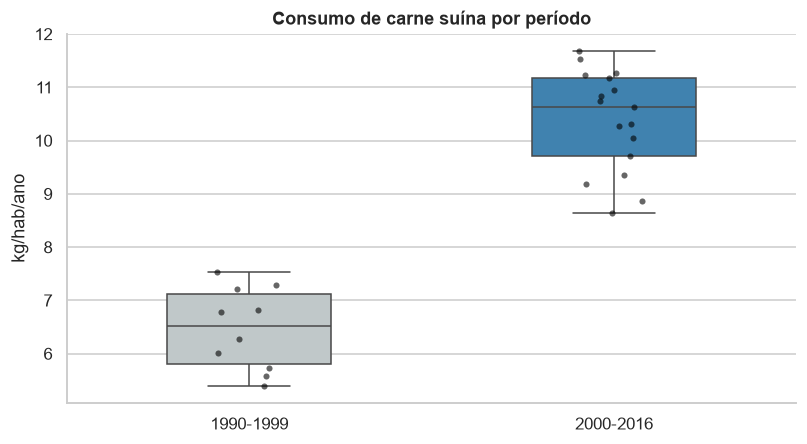

In [15]:
# 7.1 O consumo médio de carne suína mudou entre a década de 1990 e o período 2000-2016?
g90 = df_obs.loc[df_obs['Ano'] < 2000, 'Carne_Suina']; g00 = df_obs.loc[df_obs['Ano'] >= 2000, 'Carne_Suina']
ALFA = 0.05
print('Verificação das premissas')
print(f'  Shapiro-Wilk 1990-1999: p = {stats.shapiro(g90).pvalue:.3f} | 2000-2016: p = {stats.shapiro(g00).pvalue:.3f}  (p > 0,05: normalidade não rejeitada)')
print(f'  Levene (igualdade de variâncias): p = {stats.levene(g90, g00).pvalue:.3f}')

t = stats.ttest_ind(g00, g90, equal_var=False)            # teste t de Welch
ic = t.confidence_interval(0.95)
u = stats.mannwhitneyu(g00, g90, alternative='two-sided')  # alternativa não paramétrica
d_cohen = (g00.mean() - g90.mean()) / np.sqrt((g90.var(ddof=1) + g00.var(ddof=1)) / 2)
print('\nTeste t de Welch (H0: médias iguais | H1: médias diferentes)')
print(f'  Média 1990-1999 = {g90.mean():.2f} kg/hab (n = {len(g90)}) | Média 2000-2016 = {g00.mean():.2f} kg/hab (n = {len(g00)})')
print(f'  t = {t.statistic:.2f} | graus de liberdade = {t.df:.1f} | valor-p = {t.pvalue:.2e}')
print(f'  IC 95% para a diferença de médias: [{ic.low:.2f} ; {ic.high:.2f}] kg/hab | d de Cohen = {d_cohen:.1f}')
print(f'Teste de Mann-Whitney (confirmação sem supor normalidade): U = {u.statistic:.0f} | valor-p = {u.pvalue:.2e}')
print(f"Decisão (alfa = {ALFA}): {'rejeitamos H0' if t.pvalue < ALFA else 'não rejeitamos H0'}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
dados = pd.DataFrame({'Período': np.where(df_obs['Ano'] < 2000, '1990-1999', '2000-2016'), 'Consumo': df_obs['Carne_Suina']})
sns.boxplot(data=dados, x='Período', y='Consumo', palette=['#BFC9CA', CORES['Carne_Suina']], width=.45, ax=ax)
sns.stripplot(data=dados, x='Período', y='Consumo', color='black', size=4, alpha=.6, ax=ax)
ax.set_title('Consumo de carne suína por período'); ax.set_ylabel('kg/hab/ano'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

In [16]:
# 7.2 Existe relação de substituição entre as carnes? Teste de correlação nas variações anuais
var = df_obs[colunas_num].diff().dropna()
linhas = []
for a, b in [('Carne_Suina', 'Carne_Bovina'), ('Carne_Suina', 'Aves'), ('Carne_Bovina', 'Aves')]:
    r_n, p_n = stats.pearsonr(df_obs[a], df_obs[b]); r_v, p_v = stats.pearsonr(var[a], var[b])
    linhas.append({'Par': f'{ROTULOS[a]} x {ROTULOS[b]}', 'r (níveis)': r_n, 'valor-p (níveis)': p_n,
                   'r (variações anuais)': r_v, 'valor-p (variações)': p_v,
                   'Conclusão nas variações (alfa 5%)': 'correlação significativa' if p_v < ALFA else 'não significativa'})
pd.DataFrame(linhas).set_index('Par').round(4)

,r (níveis),valor-p (níveis),r (variações anuais),valor-p (variações),Conclusão nas variações (alfa 5%)
Par,,,,,
Carne suína x Carne bovina,0.834,0.000,0.330,0.100,não significativa
Carne suína x Aves,0.930,0.000,0.077,0.709,não significativa
Carne bovina x Aves,0.825,0.000,-0.310,0.123,não significativa


In [17]:
# 7.3 Intervalo de confiança para a média mundial, a partir da amostra estratificada da Seção 5
x = amostra_estrat['Carne_Suina']; n_a = len(x)
ic_simples = stats.t.interval(0.95, n_a - 1, loc=x.mean(), scale=x.std(ddof=1) / np.sqrt(n_a))
# Erro padrão próprio da amostragem estratificada (com correção de população finita em cada estrato)
Nh = df_mundo.groupby('Pais').size(); g = amostra_estrat.groupby('Pais')['Carne_Suina']
nh, s2h, mh = g.size(), g.var(ddof=1), g.mean()
media_est = ((Nh / N) * mh).sum()
ep_formula = np.sqrt((((Nh / N) ** 2) * (1 - nh / Nh) * s2h / nh).sum())
ic_est = (media_est - 1.96 * ep_formula, media_est + 1.96 * ep_formula)
print(f'Estimativa pontual da média mundial: {media_est:.2f} kg/hab/ano')
print(f'IC 95% tratando a amostra como AAS      : [{ic_simples[0]:.2f} ; {ic_simples[1]:.2f}]')
print(f'IC 95% com a fórmula da estratificação  : [{ic_est[0]:.2f} ; {ic_est[1]:.2f}]')
print(f'Média populacional verdadeira           : {mu:.2f} -> {"dentro" if ic_est[0] <= mu <= ic_est[1] else "fora"} do IC estratificado')
print(f'Média do Brasil (1990-2016)             : {bra_media:.2f} kg/hab/ano')

Estimativa pontual da média mundial: 7.91 kg/hab/ano
IC 95% tratando a amostra como AAS      : [7.01 ; 8.87]
IC 95% com a fórmula da estratificação  : [7.72 ; 8.11]
Média populacional verdadeira           : 7.97 -> dentro do IC estratificado
Média do Brasil (1990-2016)             : 8.93 kg/hab/ano


### 7.4 Leitura dos resultados

**Mudança de patamar (7.1).** As premissas foram atendidas (normalidade não rejeitada nos dois grupos; variâncias homogêneas pelo teste de Levene). O consumo médio passou de 6,46 para 10,38 kg/hab, e o teste de Welch **rejeita H0** (t = 11,68; p = 6,0 × 10⁻¹¹). Com 95% de confiança, o aumento médio está entre **3,2 e 4,6 kg/hab**. O teste de Mann-Whitney leva à mesma conclusão (p = 2,2 × 10⁻⁵), e o tamanho do efeito é muito grande (d de Cohen = 4,5): no boxplot, os dois períodos nem se sobrepõem.

*Ressalvas:* observações de anos consecutivos não são independentes, o que tende a deixar o valor-p menor do que deveria; e parte da diferença se concentra no salto de 2000, que pode ter componente metodológico. A conclusão de que o patamar mudou é robusta; a atribuição dessa mudança a hábitos de consumo é uma interpretação, não um resultado do teste.

**Substituição entre carnes (7.2).** Nos níveis, todas as correlações são significativas, mas isso reflete a tendência comum. Nas variações anuais, **nenhuma correlação é significativa** (suína × aves: r = 0,08, p = 0,71; suína × bovina: r = 0,33, p = 0,10). Não há evidência, nestes dados, de que o brasileiro troque carne suína por frango ou carne bovina de um ano para o outro. Com 26 observações o teste tem pouco poder, então efeitos pequenos podem existir sem serem detectados.

**Média mundial (7.3).** A amostra estratificada estima a média mundial em 7,91 kg/hab, com IC de 95% de **[7,72; 8,11]**, que contém o valor populacional verdadeiro (7,97). Se a mesma amostra fosse tratada como aleatória simples, o intervalo seria [7,01; 8,87], quase cinco vezes mais largo: é o ganho de precisão da estratificação, agora na forma de intervalo. A média brasileira (8,93) fica acima do limite superior do intervalo, indicando consumo acima da média mundial no período.

## 8. Modelagem preditiva e escolha do modelo

**Objetivo:** prever o consumo de carne suína do ano seguinte usando apenas informação disponível no ano corrente. Comparamos cinco modelos (regressões lineares por mínimos quadrados e uma referência ingênua):

| Modelo | Variáveis explicativas | É previsão de fato? |
|---|---|---|
| M0 – Ingênuo | Repete o valor do ano anterior | Sim (referência mínima) |
| M1 – Tendência | `Ano` | Sim |
| M2 – Outras carnes no mesmo ano | `Carne_Bovina`, `Aves` do mesmo ano | **Não**: exige dados que só existem quando o próprio consumo de suína já é conhecido |
| M3 – Autorregressivo | Carne suína do ano anterior | Sim |
| M4 – Defasado completo | Suína, bovina e aves do ano anterior | Sim |

**Critérios de escolha**
1. **Erro fora da amostra (critério principal):** RMSE das previsões 1 ano à frente com *origem móvel*: para cada ano de 2005 a 2016, o modelo é ajustado só com o passado e prevê o ano seguinte (12 previsões).
2. **Validação temporal simples:** treino em 1991–2010 e teste em 2011–2016 (RMSE e MAE).
3. **Qualidade do ajuste com penalização de complexidade:** R² ajustado, AIC e BIC no treino.
4. **Comparação com o modelo ingênuo:** um modelo só é útil se errar menos que simplesmente repetir o último valor.

A divisão entre treino e teste é cronológica, sem sorteio, para que nenhum modelo use informação do futuro.

In [18]:
# 8.1 Preparação: variáveis defasadas em 1 ano (informação disponível no momento da previsão)
df_mod = df_obs[['Ano', 'Carne_Bovina', 'Carne_Suina', 'Aves']].copy()
for c in ['Carne_Suina', 'Carne_Bovina', 'Aves']:
    df_mod[c + '_ano_anterior'] = df_mod[c].shift(1)
df_mod = df_mod.dropna().reset_index(drop=True)

MODELOS = {
    'M1 - Tendência linear (Ano)': ['Ano'],
    'M2 - Outras carnes no mesmo ano': ['Carne_Bovina', 'Aves'],
    'M3 - Carne suína do ano anterior': ['Carne_Suina_ano_anterior'],
    'M4 - Três carnes do ano anterior': ['Carne_Suina_ano_anterior', 'Carne_Bovina_ano_anterior', 'Aves_ano_anterior'],
}
E_PREVISAO = {'M0 - Ingênuo (repete o ano anterior)': 'Sim', 'M1 - Tendência linear (Ano)': 'Sim',
              'M2 - Outras carnes no mesmo ano': 'Não', 'M3 - Carne suína do ano anterior': 'Sim',
              'M4 - Três carnes do ano anterior': 'Sim'}
ALVO = 'Carne_Suina'

def ajustar(treino, variaveis):
    return sm.OLS(treino[ALVO], sm.add_constant(treino[variaveis], has_constant='add')).fit()

def prever(modelo, dados, variaveis):
    return modelo.predict(sm.add_constant(dados[variaveis], has_constant='add'))

rmse = lambda real, prev: float(np.sqrt(np.mean((np.asarray(real) - np.asarray(prev)) ** 2)))
mae = lambda real, prev: float(np.mean(np.abs(np.asarray(real) - np.asarray(prev))))

# (a) Validação temporal simples: treino 1991-2010, teste 2011-2016
CORTE = 2010
treino, teste = df_mod[df_mod['Ano'] <= CORTE], df_mod[df_mod['Ano'] > CORTE]

# (b) Validação com origem móvel: para cada ano de 2005 a 2016, ajusta com o passado e prevê 1 ano à frente
anos_alvo = list(range(2005, ULTIMO_ANO_OBSERVADO + 1))
prev_movel = {nome: [] for nome in list(MODELOS) + ['M0 - Ingênuo (repete o ano anterior)']}
for ano in anos_alvo:
    tr, te = df_mod[df_mod['Ano'] < ano], df_mod[df_mod['Ano'] == ano]
    prev_movel['M0 - Ingênuo (repete o ano anterior)'].append(float(te['Carne_Suina_ano_anterior'].iloc[0]))
    for nome, v in MODELOS.items():
        prev_movel[nome].append(float(prever(ajustar(tr, v), te, v).iloc[0]))
real_movel = df_mod.loc[df_mod['Ano'].isin(anos_alvo), ALVO].values

linhas = [{'Modelo': 'M0 - Ingênuo (repete o ano anterior)', 'Nº de variáveis': 0, 'R² ajustado (treino)': np.nan, 'AIC': np.nan, 'BIC': np.nan,
           'RMSE teste 2011-2016': rmse(teste[ALVO], teste['Carne_Suina_ano_anterior']),
           'MAE teste 2011-2016': mae(teste[ALVO], teste['Carne_Suina_ano_anterior'])}]
for nome, v in MODELOS.items():
    m = ajustar(treino, v); p = prever(m, teste, v)
    linhas.append({'Modelo': nome, 'Nº de variáveis': len(v), 'R² ajustado (treino)': m.rsquared_adj, 'AIC': m.aic, 'BIC': m.bic,
                   'RMSE teste 2011-2016': rmse(teste[ALVO], p), 'MAE teste 2011-2016': mae(teste[ALVO], p)})
tab_mod = pd.DataFrame(linhas).set_index('Modelo')
tab_mod['RMSE origem móvel 2005-2016'] = pd.Series({k: rmse(real_movel, v) for k, v in prev_movel.items()})
tab_mod['É previsão de fato?'] = pd.Series(E_PREVISAO)
print(f'Treino: {treino.Ano.min()}-{treino.Ano.max()} ({len(treino)} anos) | Teste: {teste.Ano.min()}-{teste.Ano.max()} ({len(teste)} anos)')
display(tab_mod.round(3))

candidatos = tab_mod[tab_mod['É previsão de fato?'] == 'Sim'].drop(index='M0 - Ingênuo (repete o ano anterior)')
MODELO_FINAL = candidatos['RMSE origem móvel 2005-2016'].idxmin()
print(f'Melhor modelo de previsão pelo RMSE com origem móvel: {MODELO_FINAL}')

Treino: 1991-2010 (20 anos) | Teste: 2011-2016 (6 anos)

,Nº de variáveis,R² ajustado (treino),AIC,BIC,RMSE teste 2011-2016,MAE teste 2011-2016,RMSE origem móvel 2005-2016,É previsão de fato?
Modelo,,,,,,,,
M0 - Ingênuo (repete o ano anterior),0,NaN,NaN,NaN,0.361,0.335,0.377,Sim
M1 - Tendência linear (Ano),1,0.711,58.012,60.004,0.614,0.510,0.850,Sim
M2 - Outras carnes no mesmo ano,2,0.765,54.743,57.730,0.377,0.325,0.750,Não
M3 - Carne suína do ano anterior,1,0.808,49.789,51.781,0.380,0.337,0.383,Sim
M4 - Três carnes do ano anterior,3,0.823,49.861,53.844,0.326,0.291,0.469,Sim


Melhor modelo de previsão pelo RMSE com origem móvel: M3 - Carne suína do ano anterior


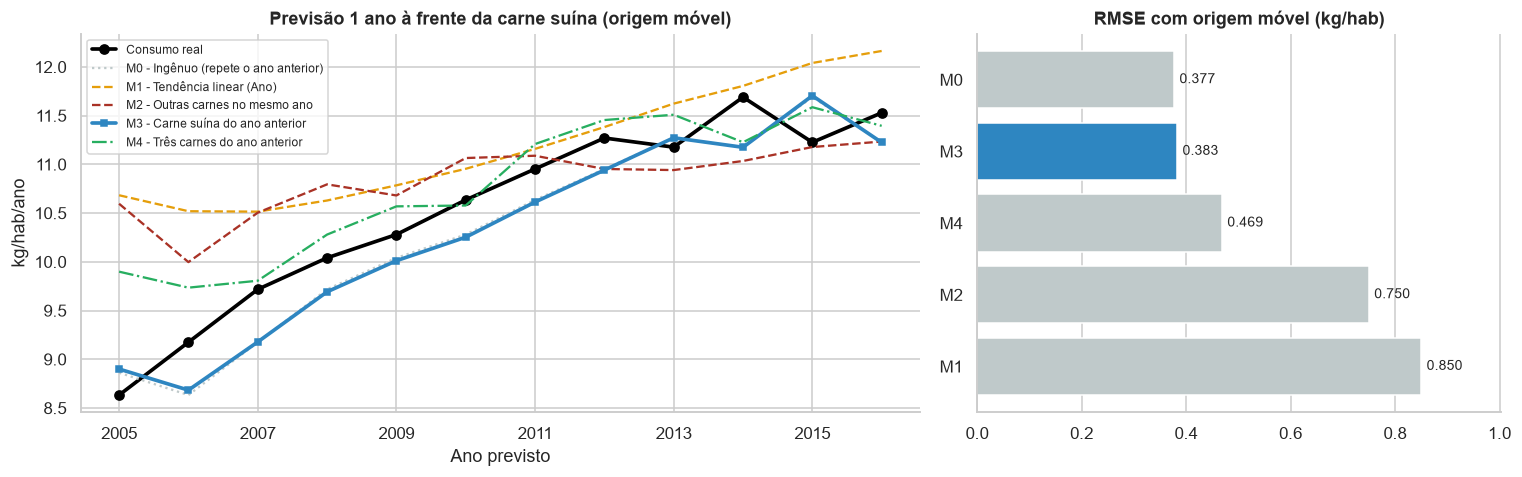

In [19]:
# 8.2 Previsões 1 ano à frente (origem móvel) x consumo real
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
axes[0].plot(anos_alvo, real_movel, color='black', lw=2.4, marker='o', label='Consumo real')
estilo = {'M0 - Ingênuo (repete o ano anterior)': ('#BFC9CA', ':'), 'M1 - Tendência linear (Ano)': ('#E59E0B', '--'),
          'M2 - Outras carnes no mesmo ano': ('#A93226', '--'), 'M3 - Carne suína do ano anterior': ('#6C7A89', '-.'),
          'M4 - Três carnes do ano anterior': ('#27AE60', '-.')}
for nome, (cor, ls) in estilo.items():
    destaque = nome == MODELO_FINAL
    axes[0].plot(anos_alvo, prev_movel[nome], color=CORES['Carne_Suina'] if destaque else cor, ls='-' if destaque else ls,
                 lw=2.4 if destaque else 1.5, marker='s' if destaque else None, ms=4, label=nome.split(' - ')[0] + ' - ' + nome.split(' - ')[1])
axes[0].set_title('Previsão 1 ano à frente da carne suína (origem móvel)'); axes[0].set_xlabel('Ano previsto')
axes[0].set_ylabel('kg/hab/ano'); axes[0].legend(fontsize=8); axes[0].set_xticks(anos_alvo[::2])

ordem = tab_mod['RMSE origem móvel 2005-2016'].sort_values()
axes[1].barh([i.split(' - ')[0] for i in ordem.index][::-1], ordem.values[::-1],
             color=[CORES['Carne_Suina'] if i == MODELO_FINAL else '#BFC9CA' for i in ordem.index][::-1])
for y, v in enumerate(ordem.values[::-1]):
    axes[1].text(v + 0.01, y, f'{v:.3f}', va='center', fontsize=9)
axes[1].set_title('RMSE com origem móvel (kg/hab)'); axes[1].set_xlim(0, ordem.max() * 1.18); axes[1].grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

M3 - Carne suína do ano anterior | n = 26 | R² = 0.881 | R² ajustado = 0.876


,Coeficiente,Erro padrão,valor-p,IC 95% inf.,IC 95% sup.
const,1.008,0.621,0.118,-0.273,2.289
Carne_Suina_ano_anterior,0.913,0.069,0.000,0.771,1.054


Resíduos -> Shapiro-Wilk: p = 0.0000 | Durbin-Watson = 1.73 (próximo de 2: sem autocorrelação)
Maior resíduo: 2.85 kg/hab no ano 2000

Previsão do modelo para 2017: 11.53 kg/hab | intervalo de previsão 95%: [9.98 ; 13.08]
Projeção OCDE-FAO para 2017 : 11.85 kg/hab (diferença de -0.32)


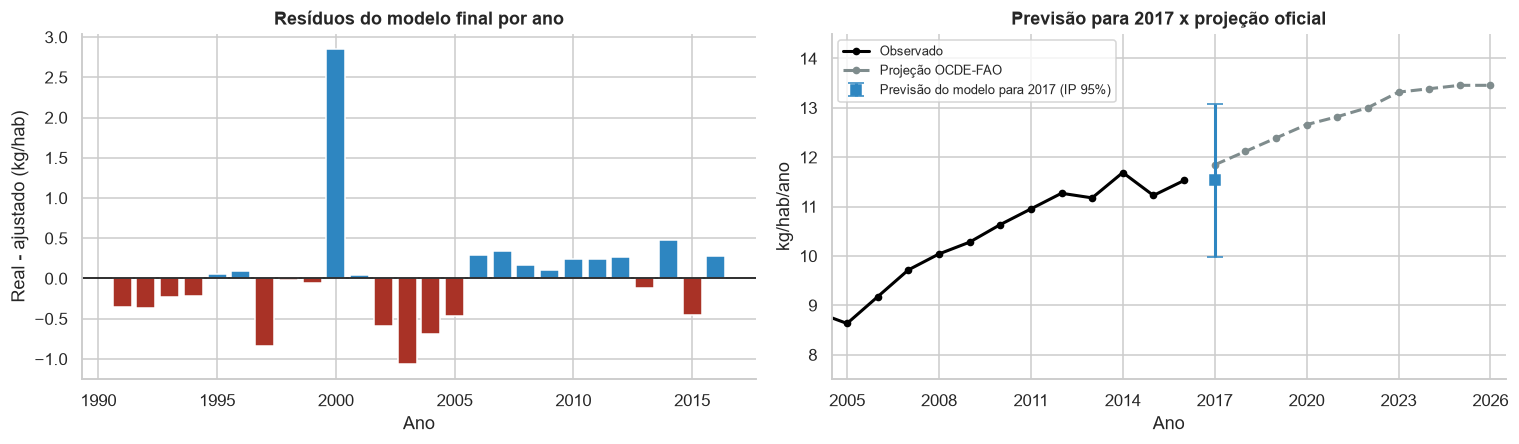

In [20]:
# 8.3 Modelo final reajustado com todo o período observado, diagnóstico dos resíduos e previsão para 2017
v_final = MODELOS[MODELO_FINAL]
modelo_final = ajustar(df_mod, v_final)
coefs = pd.DataFrame({'Coeficiente': modelo_final.params, 'Erro padrão': modelo_final.bse, 'valor-p': modelo_final.pvalues})
coefs[['IC 95% inf.', 'IC 95% sup.']] = modelo_final.conf_int()
print(f'{MODELO_FINAL} | n = {int(modelo_final.nobs)} | R² = {modelo_final.rsquared:.3f} | R² ajustado = {modelo_final.rsquared_adj:.3f}')
display(coefs.round(4))

res = modelo_final.resid
print(f'Resíduos -> Shapiro-Wilk: p = {stats.shapiro(res).pvalue:.4f} | Durbin-Watson = {durbin_watson(res):.2f} (próximo de 2: sem autocorrelação)')
print(f"Maior resíduo: {res.abs().max():.2f} kg/hab no ano {int(df_mod.loc[res.abs().idxmax(), 'Ano'])}")

# Previsão para 2017 usando apenas dados de 2016
ult = df_obs[df_obs['Ano'] == ULTIMO_ANO_OBSERVADO].iloc[0]
x_2017 = pd.DataFrame([{'Ano': 2017, 'Carne_Suina_ano_anterior': ult['Carne_Suina'],
                        'Carne_Bovina_ano_anterior': ult['Carne_Bovina'], 'Aves_ano_anterior': ult['Aves']}])
prev_2017 = modelo_final.get_prediction(sm.add_constant(x_2017[v_final], has_constant='add')).summary_frame(alpha=0.05).iloc[0]
ocde_2017 = float(df_proj.loc[df_proj['Ano'] == 2017, 'Carne_Suina'].iloc[0])
print(f"\nPrevisão do modelo para 2017: {prev_2017['mean']:.2f} kg/hab | intervalo de previsão 95%: [{prev_2017['obs_ci_lower']:.2f} ; {prev_2017['obs_ci_upper']:.2f}]")
print(f'Projeção OCDE-FAO para 2017 : {ocde_2017:.2f} kg/hab (diferença de {prev_2017["mean"] - ocde_2017:+.2f})')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(df_mod['Ano'], res, color=np.where(res >= 0, CORES['Carne_Suina'], '#A93226'))
axes[0].axhline(0, color='black', lw=1); axes[0].set_title('Resíduos do modelo final por ano')
axes[0].set_xlabel('Ano'); axes[0].set_ylabel('Real - ajustado (kg/hab)')
axes[1].plot(df_obs['Ano'], df_obs['Carne_Suina'], color='black', lw=2, marker='o', ms=4, label='Observado')
axes[1].plot(df_proj['Ano'], df_proj['Carne_Suina'], color=CINZA, lw=2, ls='--', marker='o', ms=4, label='Projeção OCDE-FAO')
axes[1].errorbar([2017], [prev_2017['mean']], yerr=[[prev_2017['mean'] - prev_2017['obs_ci_lower']], [prev_2017['obs_ci_upper'] - prev_2017['mean']]],
                 fmt='s', color=CORES['Carne_Suina'], capsize=5, ms=7, lw=2, label='Previsão do modelo para 2017 (IP 95%)', zorder=5)
axes[1].set_xlim(2004.5, 2026.5); axes[1].set_ylim(7.5, 14.5); axes[1].set_xticks(range(2005, 2027, 3))
axes[1].set_title('Previsão para 2017 x projeção oficial'); axes[1].set_xlabel('Ano'); axes[1].set_ylabel('kg/hab/ano'); axes[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

### 8.4 Leitura dos resultados

**Modelo escolhido: M3 (carne suína do ano anterior).** Entre as regressões que fazem previsão de fato, ele tem o menor RMSE com origem móvel (0,383 kg/hab) e o menor BIC, com uma única variável.

**O resultado mais importante é o que os modelos *não* conseguem fazer:**

* **Nenhuma regressão supera o modelo ingênuo.** Repetir o valor do ano anterior tem RMSE de 0,377, praticamente igual ao do M3 (0,383). O coeficiente estimado no M3 é 0,91, com intervalo de confiança que inclui 1: o modelo aprendeu, na prática, que "o consumo do próximo ano é parecido com o deste ano".
* **O consumo das outras carnes não ajuda a prever.** O M2 parece competitivo no teste de 2011–2016 (RMSE de 0,377), mas tem erro de 0,750 com origem móvel, o dobro do ingênuo, e nem é uma previsão, pois usa dados do mesmo ano. O M4, que acrescenta bovina e aves defasadas ao M3, tem o menor erro no teste único de 2011–2016 (0,326), mas piora com origem móvel (0,469), sinal de que o ganho naquele recorte não se sustenta em outros períodos. Isso é coerente com a Seção 7: sem relação de curto prazo entre as carnes, essas variáveis só acrescentam ruído.
* **A tendência linear (M1) é o pior modelo** (0,850), porque o crescimento não foi constante ao longo do período.

**Diagnóstico do M3.** O R² ajustado de 0,876 reflete sobretudo a persistência da série. O teste de Durbin-Watson (1,73) não indica autocorrelação nos resíduos. A normalidade dos resíduos é rejeitada por causa de um único ponto: o salto de 2000, com resíduo de 2,85 kg/hab. Como consequência, o intervalo de previsão é aproximado e está mais largo do que seria sem esse ano.

**Previsão para 2017.** O modelo prevê 11,53 kg/hab, com intervalo de previsão de 95% entre 9,98 e 13,08. A projeção da OCDE-FAO (11,85) fica dentro do intervalo, 0,32 kg acima da nossa estimativa pontual.

## 9. Conclusões e recomendações

### 9.1 Respostas às perguntas do projeto

1. **Como evoluiu o consumo de carne suína?** Mais que dobrou entre 1990 e 2016, de 5,4 para 11,5 kg/hab/ano. A mudança de patamar entre a década de 1990 (média de 6,5) e o período 2000–2016 (média de 10,4) é estatisticamente significativa, com aumento médio entre 3,2 e 4,6 kg/hab (IC de 95%). O Brasil consome mais que a média mundial (8,9 contra 7,9 kg/hab), mas muito menos que os maiores consumidores.
2. **O consumo se relaciona com o das outras carnes?** No longo prazo, todas as carnes relevantes cresceram juntas, com o frango à frente (+229%). No curto prazo, não encontramos evidência de substituição: as variações anuais não têm correlação significativa.
3. **É possível prever com um ano de antecedência?** Sim, com erro típico de cerca de 0,4 kg/hab (menos de 4% do consumo atual). Porém esse resultado vem da estabilidade da série, não da sofisticação do modelo: nenhuma regressão testada superou a regra de repetir o valor do ano anterior.

### 9.2 Recomendações para o setor

* **Planejamento anual:** usar o consumo do último ano como base da previsão do próximo, com margem de aproximadamente ±0,4 kg/hab em anos normais. A série mostra que choques maiores acontecem (como o de 2000), então convém manter planos de contingência.
* **Cenários:** em uma década, esperar em torno de 7 anos de alta e 3 de queda ou estabilidade. Projeções que mostram crescimento em todos os anos descrevem a tendência, não o caminho ano a ano.
* **Expansão:** o patamar de 12 kg/hab seria raro mantidas as condições de 2000–2016 (4,3%); atingi-lo de forma sustentada, como projeta a OCDE-FAO, depende da continuidade do crescimento, não de oscilação normal do mercado.

### 9.3 Limitações

* **Série curta:** 27 observações anuais limitam o poder dos testes e a complexidade dos modelos.
* **Sem variáveis econômicas:** a base não traz preços, renda ou exportações, que são os determinantes mais prováveis do consumo. As conclusões sobre substituição se referem a quantidades consumidas, não a preços.
* **Dependência temporal:** observações de anos vizinhos não são independentes, premissa dos testes t e do modelo Binomial; os valores-p devem ser lidos com cautela.
* **Salto de 2000:** pode incluir efeito de revisão metodológica da fonte.
* **Dados ausentes simulados:** as falhas foram criadas artificialmente para avaliar os métodos; 10 dos 148 valores usados são imputados.
* **Corte observado/projeção:** o ano de 2016 como limite foi inferido da descrição da base.

### 9.4 Próximos passos
Incorporar preços relativos das carnes e renda per capita (IBGE, CEPEA), usar dados trimestrais de abate para aumentar o número de observações e testar modelos próprios de séries temporais (ARIMA, suavização exponencial).

### 9.5 Fonte dos dados
OECD/FAO, *OECD-FAO Agricultural Outlook* — indicador *Meat consumption*. Base disponibilizada no Kaggle como *Worldwide Meat Consumption* (`meat_consumption_worldwide.csv`).